# Where Can London Still Afford to Buy?

## Notebook 01: Explore and clean

This notebook explores HM Land Registry Price Paid Data, decides which sales to keep, and produces a clean London dataset for analysis in MySQL.

**Audience:** a mortgage lender looking at affordability and market risk across London boroughs.

**Data:** HM Land Registry Price Paid Data, 2018 to 2026 (2026 is year to date). filtered toGreater London only.

## Business questions

1. What is the median price in each borough today?
2. How many years of local earnings does a median home cost, compared with a 4.5x mortgage?
3. How did prices change in each borough across three periods?
4. Did the pandemic shift demand from flats to houses, or from inner to outer London? Has that held since 2022?
5. Which boroughs are relatively affordable and still growing since rates rose?

## Periods

| Period | Years |
|---|---|
| Pre-COVID | 2018 to 2019 |
| Pandemic | 2020 to 2021 |
| Rate rises | 2022 to 2026 |

# values and explaination for fields

**Transaction unique identifier** :  A reference number which is generated automatically recording each published sale. The number is unique and will change each time a sale is recorded.

**Price** : Sale price stated on the transfer deed.

**Date of Transfer** : Date when the sale was completed, as stated on the transfer deed.

**Postcode** : This is the postcode used at the time of the original transaction. Note that postcodes can be reallocated and these changes are not reflected in the Price Paid Dataset.

**Property Type** : D = Detached, S = Semi-Detached, T = Terraced, F = Flats/Maisonettes, O = Other
Note that:
- we only record the above categories to describe property type, we do not separately identify bungalows
- end-of-terrace properties are included in the Terraced category above
- ‘Other’ is only valid where the transaction relates to a property type that is not covered by existing values, for example where a property comprises more than one large parcel of land

**OLD/NEW** : Indicates the age of the property and applies to all price paid transactions, residential and non-residential.
Y = a newly built property, N = an established residential building

**Duration** : Relates to the tenure: F = Freehold, L= Leasehold etc.
Note that HM Land Registry does not record leases of 7 years or less in the Price Paid Dataset.

**PAON** : Primary Addressable Object Name. Typically the house number or name.

**SAON** : Secondary Addressable Object Name. Where a property has been divided into separate units (for example, flats), the PAON (above) will identify the building and a SAON will be specified that identifies the separate unit/flat.

**PPD Category Type** : Indicates the type of Price Paid transaction.
A = Standard Price Paid entry, includes single residential property sold for value.
B = Additional Price Paid entry including transfers under a power of sale/repossessions, buy-to-lets (where they can be identified by a Mortgage), transfers to non-private individuals and sales where the property type is classed as ‘Other’.

Note that category B does not separately identify the transaction types stated.
HM Land Registry has been collecting information on Category A transactions from January 1995. Category B transactions were identified from October 2013.

**Record Status - monthly file only** : Indicates additions, changes and deletions to the records.(see guide below).
A = Addition
C = Change
D = Delete

Note that where a transaction changes category type due to misallocation (as above) it will be deleted from the original category type and added to the correct category with a new transaction unique identifier.


**taken from dataset instructions** https://www.gov.uk/guidance/about-the-price-paid-data

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [44]:
import pandas as pd

cols = [
    "transaction_id", "price", "date_of_transfer", "postcode",
    "property_type", "old_new", "duration", "paon", "saon",
    "street", "locality", "town_city", "district", "county",
    "ppd_category", "record_status",
]

df = pd.read_csv("../data/raw/pp-2025.csv", header=None, names=cols)
print(df.shape)
df.head(10)

(974087, 16)


,transaction_id,price,date_of_transfer,postcode,property_type,old_new,duration,paon,saon,street,locality,town_city,district,county,ppd_category,record_status
0,{402A3A66-B9C5-A7DF-E063-4804A8C0B80D},115000,2025-08-29 00:00,S42 5JL,T,N,F,4,NaN,NORTH STREET,NORTH WINGFIELD,CHESTERFIELD,NORTH EAST DERBYSHIRE,DERBYSHIRE,B,A
1,{402A3A66-B9C6-A7DF-E063-4804A8C0B80D},105000,2025-08-20 00:00,DE23 6SS,T,N,F,36,NaN,BELGRAVE STREET,NaN,DERBY,CITY OF DERBY,CITY OF DERBY,B,A
2,{402A3A66-B9C7-A7DF-E063-4804A8C0B80D},120000,2025-07-15 00:00,DE75 7RN,S,N,F,59,NaN,FLAMSTEAD AVENUE,LOSCOE,HEANOR,AMBER VALLEY,DERBYSHIRE,B,A
3,{402A3A66-B9C8-A7DF-E063-4804A8C0B80D},192500,2025-08-29 00:00,DE65 5GZ,D,N,F,93,NaN,WELLAND ROAD,HILTON,DERBY,SOUTH DERBYSHIRE,DERBYSHIRE,B,A
4,{402A3A66-B9C9-A7DF-E063-4804A8C0B80D},115000,2025-09-19 00:00,NG10 4LX,T,N,F,10,NaN,WELLINGTON STREET,LONG EATON,NOTTINGHAM,EREWASH,DERBYSHIRE,B,A
5,{402A3A66-B9CC-A7DF-E063-4804A8C0B80D},160000,2025-09-05 00:00,DE56 0HW,T,N,F,2,NaN,OVER LANE,NaN,BELPER,AMBER VALLEY,DERBYSHIRE,B,A
6,{402A3A66-B9CD-A7DF-E063-4804A8C0B80D},137500,2025-09-08 00:00,S41 0HB,S,N,F,27,NaN,VALLEY ROAD,NaN,CHESTERFIELD,CHESTERFIELD,DERBYSHIRE,B,A
7,{402A3A66-B9CE-A7DF-E063-4804A8C0B80D},76594,2025-08-07 00:00,DE23 6FR,F,N,L,"LIME HOUSE, 2",FLAT 3,LIME WALK,LITTLEOVER,DERBY,CITY OF DERBY,CITY OF DERBY,B,A
8,{402A3A66-B9CF-A7DF-E063-4804A8C0B80D},135000,2025-09-19 00:00,SK13 8BS,S,N,L,2 - 4,NORFOLK VIEW,NORFOLK STREET,NaN,GLOSSOP,HIGH PEAK,DERBYSHIRE,B,A
9,{402A3A66-B9D0-A7DF-E063-4804A8C0B80D},200000,2025-08-29 00:00,SK17 0TF,O,N,F,FLASH BAR STORES,NaN,NaN,QUARNFORD,BUXTON,HIGH PEAK,DERBYSHIRE,B,A


****values and explaination for fields****

**Transaction unique identifier** :  A reference number which is generated automatically recording each published sale. The number is unique and will change each time a sale is recorded.

**Price** : Sale price stated on the transfer deed.

**Date of Transfer** : Date when the sale was completed, as stated on the transfer deed.

**Postcode** : This is the postcode used at the time of the original transaction. Note that postcodes can be reallocated and these changes are not reflected in the Price Paid Dataset.

**Property Type** : D = Detached, S = Semi-Detached, T = Terraced, F = Flats/Maisonettes, O = Other
Note that:
- we only record the above categories to describe property type, we do not separately identify bungalows
- end-of-terrace properties are included in the Terraced category above
- ‘Other’ is only valid where the transaction relates to a property type that is not covered by existing values, for example where a property comprises more than one large parcel of land

**OLD/NEW** : Indicates the age of the property and applies to all price paid transactions, residential and non-residential.
Y = a newly built property, N = an established residential building

**Duration** : Relates to the tenure: F = Freehold, L= Leasehold etc.
Note that HM Land Registry does not record leases of 7 years or less in the Price Paid Dataset.

**PAON** : Primary Addressable Object Name. Typically the house number or name.

**SAON** : Secondary Addressable Object Name. Where a property has been divided into separate units (for example, flats), the PAON (above) will identify the building and a SAON will be specified that identifies the separate unit/flat.

**PPD Category Type** : Indicates the type of Price Paid transaction.
A = Standard Price Paid entry, includes single residential property sold for value.
B = Additional Price Paid entry including transfers under a power of sale/repossessions, buy-to-lets (where they can be identified by a Mortgage), transfers to non-private individuals and sales where the property type is classed as ‘Other’.

Note that category B does not separately identify the transaction types stated.
HM Land Registry has been collecting information on Category A transactions from January 1995. Category B transactions were identified from October 2013.

**Record Status - monthly file only** : Indicates additions, changes and deletions to the records.(see guide below).
A = Addition
C = Change
D = Delete

Note that where a transaction changes category type due to misallocation (as above) it will be deleted from the original category type and added to the correct category with a new transaction unique identifier.


In [45]:
pd.set_option("display.max_rows", None)
df["county"].value_counts().head(10)

county
GREATER LONDON        108179
GREATER MANCHESTER     45430
WEST YORKSHIRE         37747
WEST MIDLANDS          36741
KENT                   27841
ESSEX                  27125
LANCASHIRE             24465
HAMPSHIRE              23973
MERSEYSIDE             23342
SOUTH YORKSHIRE        22135
Name: count, dtype: int64

In [46]:
df["county"].nunique()

113

In [47]:
london = df[df["county"] == "GREATER LONDON"]
print(len(london), "London sales out of", len(df))
london["district"].value_counts()

108179 London sales out of 974087


district
WANDSWORTH                5785
CROYDON                   5214
BROMLEY                   5090
BARNET                    4706
LAMBETH                   4496
EALING                    3956
HAVERING                  3904
LEWISHAM                  3854
SOUTHWARK                 3787
WALTHAM FOREST            3575
ENFIELD                   3531
HILLINGDON                3529
TOWER HAMLETS             3495
BEXLEY                    3424
GREENWICH                 3322
HARINGEY                  3108
CITY OF WESTMINSTER       3105
RICHMOND UPON THAMES      3101
REDBRIDGE                 3019
HACKNEY                   2989
BRENT                     2967
HAMMERSMITH AND FULHAM    2960
MERTON                    2827
NEWHAM                    2809
SUTTON                    2802
HOUNSLOW                  2672
CAMDEN                    2613
HARROW                    2444
ISLINGTON                 2411
KINGSTON UPON THAMES      2316
KENSINGTON AND CHELSEA    2280
BARKING AND DAGENHAM      1846

In [48]:
london["property_type"].value_counts()

property_type
F    54232
T    28589
S    15160
O     5546
D     4652
Name: count, dtype: int64

In [49]:
london["ppd_category"].value_counts()

ppd_category
A    85904
B    22275
Name: count, dtype: int64

In [50]:
pd.set_option("display.float_format", "{:,.0f}".format)

In [51]:
london["price"].describe()

count       108,179
mean        762,874
std       3,098,634
min               1
25%         375,000
50%         510,000
75%         735,500
max     793,020,000
Name: price, dtype: float64

In [52]:
london_share = len(london) / len(df) * 100
print(f"London is {london_share:.1f}% of all sales in 2025")

London is 11.1% of all sales in 2025


In [53]:
(london["property_type"].value_counts() / len(london) * 100)

property_type
F   50
T   26
S   14
O    5
D    4
Name: count, dtype: float64

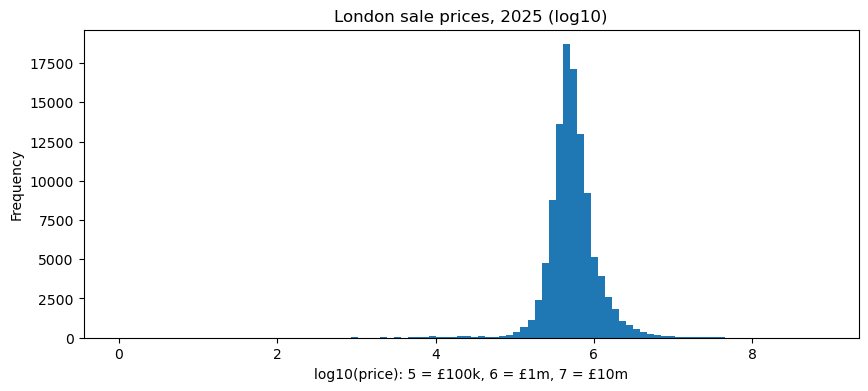

In [54]:
np.log10(london["price"]).plot(kind="hist", bins=100, figsize=(10, 4), title="London sale prices, 2025 (log10)")
plt.xlabel("log10(price): 5 = £100k, 6 = £1m, 7 = £10m")
plt.show()